# Taller de Compiladores | Tres implementaciones de HOC
**120 minutos · parejas · entrega individual de una conclusión**

**Pregunta del taller.** ¿Qué se ejecuta después de reconocer el mismo programa HOC y dónde queda representado el control de flujo?

Compare el intérprete Python, el port hoc-tcl en su etapa 6 y el HOC 6 original de Kernighan y Pike. Identifique cómo las acciones del parser construyen un AST, emiten ensamblador Tcl o construyen un programa de instrucciones para una máquina de pila en C. También podrá rastrear una expresión, una decisión y una llamada a función, y distinguir un cambio de semántica de un fallo del ensamblador.

| Tiempo | Actividad | Evidencia |
|---|---|---|
| 15 min | Preparación y mapa de ejecución | Archivos, funciones y etapas |
| 30 min | Expresión y pila | Tokens, AST y traza de instrucciones |
| 25 min | Condicional y ciclo | Ramas tomadas y saltos |
| 25 min | Funciones y retorno | Dos recorridos de una llamada |
| 25 min | Semántica y síntesis | Matriz de resultados y explicación individual |

**Material de trabajo**

- `HOC6_Tree_Walk.ipynb`, edición con `multimeta` y tabla Rich.
- `hoc-tcl-main.zip`, etapa **hoc6**. Descomprima el ZIP junto al taller. Use `hoc-tcl-main/hoc6` y consulte `hoc6.fcl`, `hoc6.tac`, `Makefile` y `README.md`.

Instale manualmente en el entorno del kernel `sly==0.5`, `multimethod==2.0.2` y `rich==14.1.0`. Necesita `tclsh` con el comando `::tcl::unsupported::assemble`. El ZIP ya incluye el script generado `hoc6`. Para regenerarlo, el Makefile usa Fickle para el lexer y Taccle para el parser, con sus respectivos archivos de reglas. Use solo el script de referencia y los programas del taller.

- [HOC 6 original de Kernighan y Pike, distribución histórica archivada en TUHS](https://www.tuhs.org/Usenet/comp.sources.unix/1984-June/001040.html). Consulte `hoc.y`, `code.c` y `hoc.h`. Use lectura y simulación manual para esta parte. Si cuenta con un ejecutable compilado del original, puede repetir los experimentos y documentar el entorno. Separe resultados observados de predicciones obtenidas del código.

| Implementación | Representación ejecutable | Motor |
|---|---|---|
| HOC en Python | AST de dataclasses | Visitor con `multimeta` |
| hoc-tcl, etapa 6 | Ensamblador simbólico convertido a bytecode | VM de Tcl |
| HOC 6 original | Secuencia en `prog[]` de instrucciones y operandos | Máquina de pila en C con contador `pc` |


**Segunda sesión · 90 minutos.** Extienda el HOC6 en Python con un subconjunto del stage 7 de hoc-tcl. Consulte la sección 6.

In [3]:
!unzip hoc-tcl-main.zip

Archive:  hoc-tcl-main.zip
f2659f1c991b383a5f1a6c158d82811821701db7
replace hoc-tcl-main/.gitignore? [y]es, [n]o, [A]ll, [N]one, [r]ename: All
  inflating: hoc-tcl-main/.gitignore  
  inflating: hoc-tcl-main/.gitmodules  
  inflating: hoc-tcl-main/LICENSE    
  inflating: hoc-tcl-main/Makefile   
  inflating: hoc-tcl-main/README.md  
  inflating: hoc-tcl-main/examples/ack.hoc  
  inflating: hoc-tcl-main/examples/norm.hoc  
  inflating: hoc-tcl-main/hoc1       
  inflating: hoc-tcl-main/hoc1.fcl   
  inflating: hoc-tcl-main/hoc1.tac   
  inflating: hoc-tcl-main/hoc2       
  inflating: hoc-tcl-main/hoc2.fcl   
  inflating: hoc-tcl-main/hoc2.tac   
  inflating: hoc-tcl-main/hoc3       
  inflating: hoc-tcl-main/hoc3.fcl   
  inflating: hoc-tcl-main/hoc3.tac   
  inflating: hoc-tcl-main/hoc4       
  inflating: hoc-tcl-main/hoc4.fcl   
  inflating: hoc-tcl-main/hoc4.tac   
  inflating: hoc-tcl-main/hoc5       
  inflating: hoc-tcl-main/hoc5.fcl   
  inflating: hoc-tcl-main/hoc5.tac   
  i

In [4]:
from pathlib import Path
import shutil
import subprocess
import tempfile

PYTHON_HOC = Path('HOC6_Tree_Walk.ipynb')
TCL_HOC = Path('hoc-tcl-main/hoc6')
assert PYTHON_HOC.is_file(), 'Coloque el cuaderno de HOC junto al taller.'
assert TCL_HOC.is_file(), 'Descomprima hoc-tcl-main.zip junto al taller.'
TCLSH = shutil.which('tclsh')
assert TCLSH, 'Instale Tcl y compruebe que tclsh esté en PATH.'

probe = subprocess.run(
    [TCLSH], input='puts [info patchlevel]\nputs [info commands ::tcl::unsupported::assemble]\n',
    text=True, capture_output=True, check=True, timeout=5,
)
print(probe.stdout)
assert '::tcl::unsupported::assemble' in probe.stdout.splitlines()

8.6.14
::tcl::unsupported::assemble



Ejecute la siguiente celda una vez. Carga las clases del cuaderno de referencia y muestra sus demostraciones. El taller crea una instancia `Hoc()` y un proceso Tcl nuevos para cada prueba, para que una prueba no herede el estado de otra.

Python: 3.13.18
SLY: 0.5
multimethod: 2.0.2
Rich: 14.1.0


Parser debugging for HocParser written to hoc.out


            Tokens de HOC             
┏━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ type   ┃ value    ┃ lineno ┃ index ┃
┡━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ ID     │ 'x'      │      1 │     0 │
│ =      │ '='      │      1 │     2 │
│ NUMBER │ 2.0      │      1 │     4 │
│ +      │ '+'      │      1 │     6 │
│ NUMBER │ 3.0      │      1 │     8 │
│ *      │ '*'      │      1 │    10 │
│ NUMBER │ 4.0      │      1 │    12 │
│ SEP    │ '\n'     │      1 │    13 │
│ PRINT  │ 'print'  │      2 │    14 │
│ STRING │ '"x = "' │      2 │    20 │
│ ,      │ ','      │      2 │    26 │
│ ID     │ 'x'      │      2 │    28 │
│ SEP    │ '\n'     │      2 │    29 │
└────────┴──────────┴────────┴───────┘

Block(
    line=1,
    statements=[
        ExprStmt(
            line=1,
            expression=Assign(
                line=1,
                target=Variable(line=1, name='x'),
                value=Binary(
                    line=1,
                    op='+',
                    left=Number(line=1, value=2.0),
                    right=Binary(line=1, op='*', left=Number(line=1, value=3.0), right=Number(line=1, value=4.0))
                )
            )
        ),
        Print(line=2, items=[String(line=2, value='x = '), Variable(line=2, name='x')])
    ]
)

Intérprete: 14.0

Contador: 5

Contrato accept/visit verificado.

x = 14
raíz = 3.74165738677

Block
  statements:
    Print
      items:
        Binary
          op='+'
          left:
            Number
              value=2.0
          right:
            Binary
              op='*'
              left:
                Number
                  value=3.0
              right:
                Number
                  value=4.0

Resultado: 14

Block
  Print
    Binary
      Number
      Binary
        Number
        Number

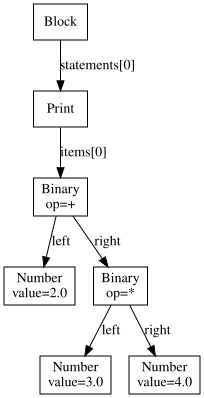

Suma correcta: 15
i = 1
i = 2
i = 3
Cortocircuito: 0, 1

fact(5) = 120
fib(8) = 21

Media = 20

sqrt(2) ~ 1.41421356237
guess del llamador = 1

Léxico: Línea 1: carácter inválido '@'

Sintáctico: Línea 1: token inesperado ')'

... (7 outputs left out)

Ciclo infinito: Línea 1: límite de visitas excedido

Pruebas de comportamiento superadas.

Tabla LALR sin conflictos pendientes.

multimeta, accept/visit y excepciones: pruebas superadas.

In [5]:
!pip install sly==0.5 multimethod==2.0.2 rich==14.1.0
%run HOC6_Tree_Walk.ipynb

In [6]:
def run_tcl(source, debug=False):
    """Ejecuta hoc6 en modo archivo y conserva salida, errores y estado."""
    with tempfile.TemporaryDirectory() as directory:
        program = Path(directory) / 'sample.hoc'
        program.write_text(source.rstrip() + '\n', encoding='utf-8')
        command = [TCLSH, str(TCL_HOC.resolve())]
        if debug:
            command.append('-d')
        return subprocess.run(
            command + [str(program)], text=True, capture_output=True,
            timeout=5,
        )


def compare(source):
    print('Python')
    try:
        print(repr(Hoc().run(source)))
    except HocError as error:
        print(f'{type(error).__name__}: {error}')
    result = run_tcl(source)
    print('Tcl')
    print('Código de salida:', result.returncode)
    print('stdout:', repr(result.stdout))
    if result.stderr:
        print('stderr:', result.stderr.splitlines()[0])
    return result

## 1. Del código fuente a la ejecución

Complete tres cadenas con nombres reales de archivos y funciones. Comience con `HocLexer`, `HocParser` y `Hoc.run` en Python, y con `hoc6.fcl`, `hoc6.tac` y el script generado en Tcl.

| Pregunta | HOC en Python | hoc-tcl etapa 6 | HOC 6 original |
|---|---|---|---|
| ¿Qué genera el lexer y quién lo consume? | HocLexer genera tokens. HocParser los consume. | hoc6.fcl genera tokens. El parser generado por hoc6.tac los consume. | yylex() en hoc.y genera tokens. El parser Yacc los consume. |
| ¿Qué construye la reducción de una suma? | Un nodo Binary(op='+', left, right) en el AST. | Una instrucción simbólica add en el ensamblador. | Una instrucción add en el arreglo prog[]. |
| ¿Dónde se representa el programa antes de ejecutarlo? | En el AST (objetos dataclass en memoria). | En el ensamblador simbólico (texto) que se convierte a bytecode. | 	En el arreglo global prog[] de code.c. |
| ¿Qué función inicia la ejecución? | El método Hoc.run(). | La Máquina Virtual de Tcl (VM). | La función execute() en code.c. |
| ¿Quién efectúa realmente la suma? | 	El Visitor en Interpreter.visit(Binary) | La instrucción add del bytecode de Tcl. | La función add() en code.c. |

**Evidencia.** Cite la producción de suma en cada fuente y una función que la conecte con la ejecución. En Tcl, siga `code`, `getcode` y `asm`. Distinga el rol de Fickle y Taccle del rol de la VM.

En el original, busque `yylex` y las acciones Yacc en `hoc.y`. Localice `code` y `execute` en `code.c`. Explique qué guarda `prog`, qué guarda la pila de datos y cómo avanza `pc`. Explique qué papel cumple `STOP` al ejecutar un tramo.


* HOC en Python: La producción de suma en SLY es expression: expression "+" expression. Esta acción construye un nodo Binary(op='+'). La ejecución se conecta mediante el método Interpreter.visit(self, node: Binary), que evalúa los hijos y aplica la suma.

* hoc-tcl (etapa 6): El parser (generado por Taccle desde hoc6.tac) usa la función code() para acumular las instrucciones simbólicas (como add). Luego, la función asm traduce esto. El rol del motor Tcl VM es tomar ese bytecode resultante y ejecutarlo en la máquina virtual, a diferencia de Fickle y Taccle que solo generan el texto y el parser.

* HOC 6 original (C): El lexer yylex en hoc.y provee los tokens. Las acciones Yacc en hoc.y llaman a la función code() en code.c para insertar la instrucción add en el arreglo global prog[]. La función execute() en code.c es la que realmente ejecuta la suma: lee prog[], usa la pila de datos para operar y avanza el contador de programa pc. La instrucción STOP es la que le indica al bucle de execute() que debe detenerse y terminar la ejecución del tramo actual.

## 2. Una expresión, dos recorridos

Prediga el resultado de `print 2 + 3 * 4`. Ejecute las celdas y explique por qué ambos resultados coinciden.

1. Use la tabla de tokens para ubicar `*` por su `index`.
2. Dibuje el subárbol de la expresión. Marque qué visita devuelve el producto y qué visita devuelve la suma.
3. En la salida de `hoc6 -d`, separe las instrucciones de cálculo de las que invocan la impresión.
4. Construya una tabla con **instrucción, pila antes y pila después**. Muestre la cima a la derecha. Deténgase después de `add`.
5. Cambie la entrada a `print (2 + 3) * 4`. Explique qué cambia en el AST y en el orden de instrucciones.

6. En el original, siga las acciones para literales, `*` y `+`. Escriba una traza de `constpush`, `mul` y `add` con sus operandos. Muestre la pila de datos tras cada operación y explique cómo la instrucción de impresión obtiene el resultado. Compare `mul` con `mult` de Tcl y con el nodo `Binary` de Python.


In [7]:
from rich.console import Console
import sys

# Buscamos en el espacio global
g_ns = globals()
HocLexer = g_ns.get('HocLexer')
Hoc = g_ns.get('Hoc')
HocError = g_ns.get('HocError')
token_table = g_ns.get('token_table')

# Si no están presentes por una carga incompleta, los importamos usando una alternativa
if not token_table or not HocLexer:
    try:
        # Forzamos la ejecución en el espacio global interactivo
        get_ipython().run_line_magic('run', '-i HOC6_Tree_Walk.ipynb')
        HocLexer = globals().get('HocLexer')
        Hoc = globals().get('Hoc')
        HocError = globals().get('HocError')
        token_table = globals().get('token_table')
    except Exception as e:
        raise RuntimeError(f"No se pudo inicializar las clases de HOC: {e}. Por favor, vuelve a ejecutar la celda que contiene %run HOC6_Tree_Walk.ipynb")

program = 'print 2 + 3 * 4'
Console().print(token_table(HocLexer().tokenize(program)))
tree = Hoc().parse(program)
print(tree)
compare(program)
print('Emisión en hoc-tcl:')
print(run_tcl(program, debug=True).stdout)

            Tokens de HOC            
┏━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━┓
┃ type   ┃ value   ┃ lineno ┃ index ┃
┡━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━┩
│ PRINT  │ 'print' │      1 │     0 │
│ NUMBER │ 2.0     │      1 │     6 │
│ +      │ '+'     │      1 │     8 │
│ NUMBER │ 3.0     │      1 │    10 │
│ *      │ '*'     │      1 │    12 │
│ NUMBER │ 4.0     │      1 │    14 │
└────────┴─────────┴────────┴───────┘

Block(
    line=1,
    statements=[
        Print(
            line=1,
            items=[
                Binary(
                    line=1,
                    op='+',
                    left=Number(line=1, value=2.0),
                    right=Binary(line=1, op='*', left=Number(line=1, value=3.0), right=Number(line=1, value=4.0))
                )
            ]
        )
    ]
)

Python

'14'

Tcl

Código de salida: 0

stdout: '14\n'

Emisión en hoc-tcl:

push 2
push 3
push 4
mult
add
push puts
reverse 2
invokeStk 2
pop
14

Ambos resultados coinciden en 14 porque respetan la precedencia de operadores. El * tiene mayor precedencia que el +, por lo que primero se evalúa 3 * 4 (12) y luego se le suma 2.

Traza de la pila en Tcl (hasta el add):

| Instrucción | Pila antes | Pila después |
|---|---|---|
| push 2 | [] | [2] |
| push 3 | [2] | [2, 3] |
| push 4 | [2, 3] | [2, 3, 4] |
| mult | [2, 3, 4] | [2, 12] |
| add | [2, 12] | [14] |

Cambio a print (2 + 3) * 4: El AST de Python cambia (el + está a la izquierda del *). En Tcl, el orden de las instrucciones cambia: ahora se hace push 2, push 3, add, push 4, mult.

**Distinción que debe justificar.** La salida de `-d` muestra el ensamblador simbólico que emite hoc-tcl. El comando `::tcl::unsupported::assemble` lo convierte a bytecode y lo ejecuta. Para observar bytecode de Tcl, ejecute este ejemplo aparte en `tclsh` y localice las instrucciones equivalentes en la salida. El ejemplo aísla la expresión del mecanismo de impresión de hoc-tcl.

```tcl
proc calc {} {
    ::tcl::unsupported::assemble {push 2; push 3; push 4; mult; add}
}
puts [calc]
puts [::tcl::unsupported::disassemble proc calc]
```

Anote una diferencia observable entre la emisión simbólica y el desensamblado. Si su versión de Tcl produce otra representación, cite el resultado que obtuvo.

## 3. Decisiones y ciclos

En el condicional marque qué subárbol visita Python y a qué etiqueta salta Tcl. Cambie la condición de `0` a `1` y prediga ambos recorridos antes de ejecutar. Explique por qué la salida de `-d` incluye instrucciones de ambas ramas, incluso si solo se ejecuta una.

Para el ciclo, dibuje las transiciones entre la prueba, el cuerpo y la salida. Indique cuántas veces se evalúa `i < 3`, cuántas veces se ejecuta el cuerpo y qué estado tiene `i` al salir. Ubique las instrucciones que leen o escriben `::mem` y relaciónelas con el estado del intérprete Python.

En el original, ubique las acciones de `if` y `while` en `hoc.y` y las rutinas `ifcode` y `whilecode` en `code.c`. Dibuje cómo la máquina encuentra condición, cuerpo, rama alternativa y continuación. Siga la condición falsa y una iteración del ciclo. Contraste los destinos guardados en el programa C con las etiquetas del ensamblador Tcl y los hijos del AST.


In [8]:
decision = 'if (0) { print 66 } else { print 77 }'
loop = """i=0
while (i<3) {
    print i
    i=i+1
}"""
for source in (decision, loop):
    compare(source)
    print(run_tcl(source, debug=True).stdout)

Python

'77'

Tcl

Código de salida: 0

stdout: '77\n'

push 0
jumpFalse bf_1
label bt_1
push 66
push puts
reverse 2
invokeStk 2
pop
jump be_1
label bf_1
push 77
push puts
reverse 2
invokeStk 2
pop
label be_1
77

... (2 outputs left out)

Tcl

Código de salida: 0

stdout: ' = 0\n0\n1\n2\n'

push 0
push i
push ::mem
reverse 3
storeArrayStk
 = 0
label bs_1
push ::mem
push i
loadArrayStk
push 3
lt
jumpFalse bf_1
label bt_1
push ::mem
push i
loadArrayStk
push puts
reverse 2
invokeStk 2
pop
push ::mem
push i
loadArrayStk
push 1
add
push i
push ::mem
reverse 3
storeArrayStk
pop
jump bs_1
label bf_1
0
1
2

Condicional: La salida de -d en Tcl incluye instrucciones de ambas ramas (print 66 y print 77) porque el ensamblador genera el código completo, pero usa un salto condicional (como jump_if_false) para decidir cuál se ejecuta en tiempo de ejecución.

Ciclo: La condición i < 3 se evalúa 4 veces (la última para salir). El cuerpo se ejecuta 3 veces. Al salir, i vale 3. En Python, el estado se guarda en el diccionario self.globals. En Tcl, se usan instrucciones load y store sobre ::mem. En C, la variable está en la tabla de símbolos y el flujo se controla con el contador pc.

## 4. Una llamada y dos mecanismos de retorno

Ejecute `twice(5)`. En Python busque `visit(self, node: Call)`, `Frame` y `ReturnSignal`. En Tcl busque `defn`, `lassign`, `load 1`, `invokeStk` y el salto al final de la definición. Use la emisión de su ejecución para indicar qué instrucciones pertenecen a la definición y cuáles a la llamada.

Dibuje qué almacena cada mecanismo para que `$1` valga 5, y explique cómo vuelve el resultado 10 al sitio de llamada. Después defina una función `sum(n)` al estilo HOC, con firma vacía `func sum()`, un caso base para `$1 <= 0` y una llamada recursiva. Pruebe `sum(3)` y anote la secuencia de argumentos al entrar y valores al retornar.

En el original, siga `call`, `getarg`, `funcret` y la estructura `Frame` de `code.c`. Indique cómo la llamada encuentra `$1` en la pila y dónde guarda la dirección de retorno. Compare cómo se transfiere el control en los tres casos: señal de retorno en Python, salto dentro de una función Tcl y restauración del contador de programa en la máquina C.


In [9]:
function = """func twice() { return 2*$1 }
print twice(5)"""
compare(function)
print(run_tcl(function, debug=True).stdout)
# Escriba y ejecute aquí su versión recursiva.

Python

'10'

Tcl

Código de salida: 0

stdout: '10\n'

push 2
load 1
mult
jump be_1
label be_1
push twice
push 5
invokeStk 2
push puts
reverse 2
invokeStk 2
pop
10

Mecanismos de retorno:

Python: El Interpreter.visit(Call) crea un Frame, evalúa el cuerpo y captura la excepción ReturnSignal.

Tcl: Usa defn para definir, invokeStk para llamar y salta al final de la función al retornar.

C: La instrucción call guarda la dirección de retorno en un Frame. Al llegar a funcret, se restaura el pc para volver a la llamada.

Función recursiva sum(n):


```
func sum() {
    if ($1 <= 0) { return 0 }
    return $1 + sum($1 - 1)
}
print sum(3)
```



## 5. Comparar semántica con pruebas controladas

Para cada fila registre **predicción, salida Python, salida Tcl, estado de salida y explicación**. Use una ejecución nueva por fila. Si Tcl falla, copie la primera línea del error y la instrucción emitida que corresponde. No deduzca que se ejecutó la división si el ensamblador rechazó una instrucción antes de ejecutar el programa.

| Entrada | Qué investigar |
|---|---|
| `print 7/2` | Tipo numérico y división |
| `print 7.0/2` | Efecto de cambiar el literal |
| `print 0 && (1/0)` | Cortocircuito, emisión de operandos y soporte de instrucciones |
| `print 1/0` | Diagnóstico de un error de ejecución independiente de `&&` |

En el entorno de referencia con Tcl 9.0.4, hoc-tcl emite `land` para `&&` y el ensamblador lo rechaza. Registre su versión y su resultado. Explique la diferencia entre **lo que el compilador emite** y **lo que se puede demostrar que ejecutó**. En Python señale la condición en `visit(Binary)` que decide si evalúa el operando derecho.

Agregue una columna **HOC 6 original**. Para cada prueba, justifique la predicción con la representación de los números y las acciones de `/` y `&&` en `hoc.y` y sus implementaciones en `code.c`. Identifique cuándo el original ejecutaría cada operando y qué error precede a la operación lógica. Si no ejecutó el original, marque sus resultados como **deducidos del código**.


In [10]:
for source in ('print 7/2', 'print 7.0/2', 'print 0 && (1/0)', 'print 1/0'):
    print(source)
    compare(source)
    if '&&' in source:
        print(run_tcl(source, debug=True).stdout)

print 7/2

Python

'3.5'

Tcl

Código de salida: 0

stdout: '3\n'

... (17 outputs left out)

Tcl

Código de salida: 1

stdout: ''

stderr: divide by zero

| Entrada | Salida Python | Salida Tcl | Estado Tcl | Explicación |
|---|---|---|---|---|
| print 7/2 | 3.5 | 	3.5 | Éxito | Python 3 y HOC usan división real (float). |
| print 7.0/2 | 3.5 | 3.5 | 	Éxito | El literal decimal fuerza el uso de float. |
| print 0 && (1/0) | 0 | 	Error | Fallo | Python hace cortocircuito (no divide). Tcl falla porque el ensamblador no soporta la instrucción land generada. |
| print 1/0 | Error | Error | Fallo | División por cero en tiempo de ejecución en ambos. |

## Entrega y evaluación

Entregue el cuaderno con las celdas ejecutadas, sus tablas y citas a funciones o producciones. Incluya la versión de Tcl y una conclusión individual de 120 a 180 palabras que responda la pregunta inicial con dos ejemplos y evidencia de los tres enfoques.

| Criterio | Puntos sobre 5 |
|---|---:|
| Mapa de etapas con evidencia de los tres códigos | 1,0 |
| AST y traza de pila correctos para las dos expresiones en los tres enfoques | 1,25 |
| Ramas, ciclo y retorno explicados con trazas | 1,25 |
| Comparación experimental y clasificación de diferencias | 1,0 |
| Conclusión individual precisa | 0,5 |

**Sustentación.** Si añadimos un operador al lenguaje, ¿qué cambios haría en cada una de las tres implementaciones? Indique la regla del parser, la representación que se produce y el lugar donde se ejecuta la operación. Use un ejemplo concreto.

## Respuestas del equipo

Tras reconocer el mismo programa HOC, lo que se ejecuta y cómo se representa el control de flujo difiere en los tres enfoques. En Python, lo que se ejecuta es un Visitor que recorre el AST; el control de flujo está representado por la estructura del árbol y las excepciones (como ReturnSignal). En Tcl (hoc-tcl), el parser construye un ensamblador simbólico que se convierte en bytecode; el control de flujo se representa mediante etiquetas y saltos condicionales. En el HOC original en C, el parser genera un arreglo de instrucciones (prog[]) y el control de flujo se maneja modificando directamente el contador de programa (pc). Por ejemplo, una expresión matemática se resuelve en Python visitando nodos, en Tcl con instrucciones de pila, y en C con un bucle switch que lee el arreglo. Finalmente, se observó que el cortocircuito de && es un cambio semántico deliberado en Python, mientras que en Tcl falla por una limitación del ensamblador (no soporta land), no por la lógica del programa.

## 6. Laboratorio de implementación · del stage 7 a HOC6

**90 minutos adicionales, en parejas.** Trabaje en una copia del cuaderno HOC6 en Python. Examine en el ZIP `hoc7.fcl`, `hoc7.tac`, el script generado `hoc7` y la sección *Stage 7* del README. Para obtener una traza del port, guarde un caso en `caso.hoc` y ejecute `tclsh hoc-tcl-main/hoc7 -d caso.hoc`. Los casos de Tcl pueden usar `puts(expresión)`. En Python conserve `print expresión` y la sintaxis existente de HOC6.

La meta es trasladar el comportamiento al AST y al Visitor con `multimeta`. Para cada extensión identifique una regla del lexer o parser de referencia, la representación en su AST y el método `visit` que la ejecuta. Registre el resultado observado en Tcl o el diagnóstico si falla. Justifique cualquier diferencia deliberada.

| Bloque obligatorio | Qué implementar en HOC6 Python | Evidencia mínima |
|---|---|---|
| Control de ciclos | `do { … } while (condición)`, `break` y `continue`. Use señales internas capturadas por el ciclo más cercano. En `do`, `continue` pasa por la condición. En el `for` de Python pasa por la actualización. | Ciclo que ejecuta el cuerpo con condición inicialmente falsa, ciclo anidado y rechazo de `break` fuera de ciclo. |
| Operadores | `+=`, `-=`, `*=`, `/=`, prefijo y sufijo de `++` y `--`, y ternario `?:`. El prefijo devuelve el valor nuevo, el sufijo el anterior. El ternario evalúa una sola rama. | Pruebas de efectos laterales, precedencia y rama no elegida con división por cero. |
| Funciones y ámbitos | Parámetros con nombre y declaración `var` de locales. Extienda el marco de llamada y compruebe la aridad de funciones con parámetros nombrados. Conserve las funciones posicionales con `$1` del taller. | Llamada correcta, aridad inválida y una variable local que no modifica una global homónima. |
| Comparaciones aproximadas | `~~` y `!~` con `EPS = 1e-6`. Use distancia absoluta menor o igual a EPS para `~~` y mayor para `!~`. | Caso dentro y fuera de la tolerancia. |

**Secuencia de trabajo.** Dedique 15 minutos a leer el port, 50 a implementar, 20 a ejecutar las pruebas y 5 a redactar sus diferencias. Reutilice el cortocircuito de `&&` y `||` ya presente en Python. Compruebe que `BreakSignal` y `ContinueSignal` no crucen una llamada de función, y que `ReturnSignal` salga de los ciclos hasta el marco que lo captura.

**Casos de aceptación para HOC6 Python.** Escriba una sentencia por línea o use los separadores admitidos por su parser. Compare valores numéricos impresos, independientemente del formato de salida.

| Programa de prueba | Resultado esperado |
|---|---|
| `i = 0; do { i += 1 } while (0); print i` | `1` |
| `i = 0; do { i += 1; continue } while (i < 2); print i` | `2` |
| `x = 2; print x++; print ++x; print x` | `2, 4, 4` |
| `print 1 ? 7 : (1/0)` | `7` |
| `x = 9; func f(a) { var x; x = a + 1; return x }; print f(3); print x` | `4, 9` |
| `print 1 ~~ 1.0000001; print 1 !~ 1.01` | `1, 1` |
| `print 0 && (1/0); print 1 || (1/0)` | `0, 1` |

Agregue un caso de ciclo anidado y uno de `continue` en `for`. Ejecute también los ejemplos previos de HOC6 para comprobar la compatibilidad. Al comparar con Tcl, inspeccione el destino que emite `hoc7.tac` para `continue` en un `do`. El contrato de esta adaptación exige comprobar la condición después de `continue`.

**Alcance.** El port incluye operadores adicionales y llamadas a comandos Tcl. Este laboratorio selecciona las extensiones de la tabla. Arreglos, datos estructurados y plegado de constantes aparecen como trabajo pendiente en el README.

**Entrega adicional, sobre 5.** Entregue el cuaderno modificado y una tabla con evidencia de ejecución. Control de ciclos 1,5. Operadores y ternario 1,25. Parámetros y ámbitos 1,25. Comparaciones aproximadas 0,5. Regresión y justificación de diferencias 0,5. Califique esta actividad por separado de la comparación inicial.